# Vision-Based Autonomous Driving Perception and Lane Guidance System
**IPCV Lab Project — JIIT Noida**  
Lavesh Goyal (2401200061) · Mehak Gupta (2401200034) · Navya Sachdeva (2401200037) — Batch G2

This notebook walks through every stage of the pipeline on real road frames:

`ROAD VIDEO → FRAME EXTRACTION → PREPROCESSING → LANE DETECTION + OBJECT DETECTION + TRAFFIC-SIGNAL ANALYSIS → TRACKING / PROXIMITY → DECISION → MAINTAIN / STEER / SLOW DOWN / STOP`

> Run `python scripts/download_samples.py` and `python scripts/generate_synthetic_video.py` once before running this notebook.

In [1]:
import os, sys
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)
import cv2, numpy as np, matplotlib.pyplot as plt
from src.config import Config
from src.preprocessing import preprocess
from src.lane_detection import LaneDetector
from src.traffic_light import classify_crop, color_masks
from src.pipeline import PerceptionPipeline, run_video
plt.rcParams['figure.dpi'] = 90
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

def read_frame(path, idx):
    cap = cv2.VideoCapture(path); cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, f = cap.read(); cap.release(); return f

cfg = Config()
frame = read_frame('data/project_video.mp4', 600)
print('original frame:', frame.shape)

original frame: (720, 1280, 3)


## 1–2. Frame extraction and image preprocessing
Resize → CLAHE contrast enhancement (LAB L-channel) → grayscale → Gaussian blur → Otsu threshold; HSV/HLS conversions are kept for colour segmentation.

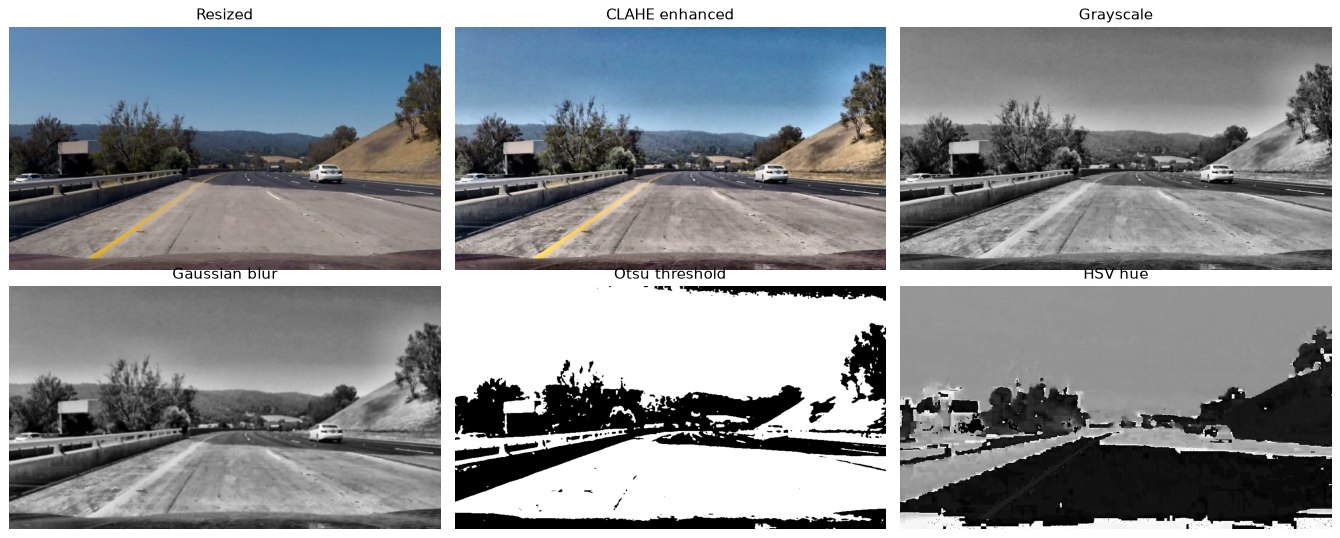

In [2]:
pre = preprocess(frame, cfg)
imgs = [('Resized', rgb(pre.frame)), ('CLAHE enhanced', rgb(pre.enhanced)), ('Grayscale', pre.gray),
        ('Gaussian blur', pre.blurred), ('Otsu threshold', pre.binary), ('HSV hue', pre.hsv[:, :, 0])]
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for a, (t, im) in zip(ax.ravel(), imgs):
    a.imshow(im, cmap='gray' if im.ndim == 2 else None); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()

## 3. Lane detection
White/yellow colour thresholding + morphology → Canny edges → trapezoidal ROI → probabilistic Hough transform → slope-based left/right split → weighted line fit → lane centre and lateral offset.

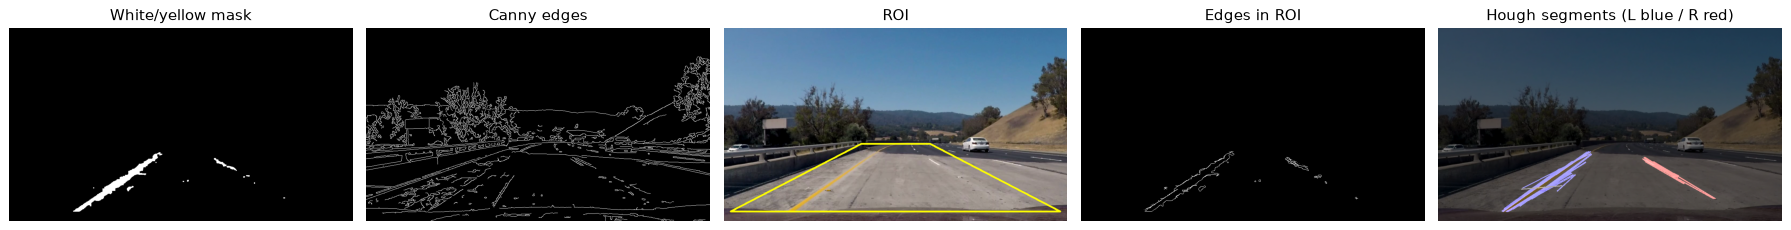

status=BOTH  offset=-0.17 m (-4.7% of lane)  heading=-8.1 deg


In [3]:
lane = LaneDetector(cfg).detect(pre)
h, w = pre.gray.shape
roi_vis = pre.frame.copy()
cv2.polylines(roi_vis, [np.array(cfg.roi_vertices(w, h), np.int32)], True, (0, 255, 255), 3)
imgs = [('White/yellow mask', lane.debug['color_mask']), ('Canny edges', lane.debug['edges']),
        ('ROI', rgb(roi_vis)), ('Edges in ROI', lane.debug['masked_edges']),
        ('Hough segments (L blue / R red)', rgb(cv2.addWeighted(pre.frame, .5, lane.debug['hough'], 1, 0)))]
fig, ax = plt.subplots(1, 5, figsize=(20, 3.4))
for a, (t, im) in zip(ax, imgs):
    a.imshow(im, cmap='gray' if im.ndim == 2 else None); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()
print(f"status={lane.status}  offset={lane.offset_m:+.2f} m ({lane.offset_norm*100:+.1f}% of lane)  heading={lane.heading_deg:+.1f} deg")

## 4. Traffic-signal analysis (HSV segmentation)
Lit lamps are bright and saturated; HSV ranges for red (two hue bands), yellow and green produce masks whose pixel ratios classify the light.

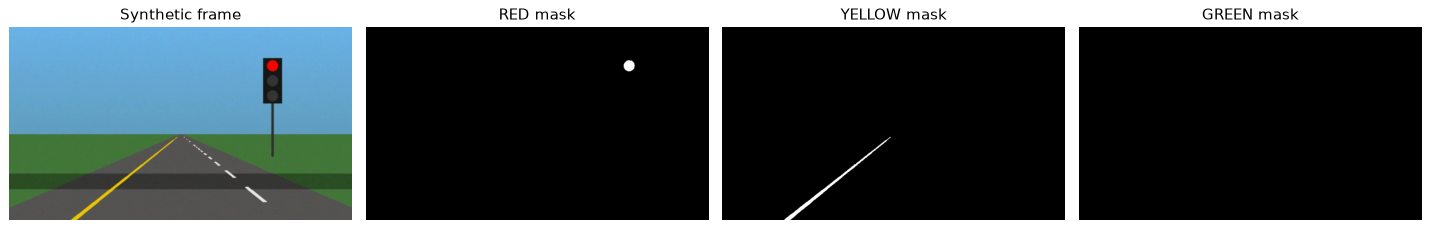

frame 100: lamp at (663, 144, 744, 225) -> GREEN  (ground truth GREEN)  RED=0.00, YELLOW=0.00, GREEN=0.09
frame 260: lamp at (682, 107, 769, 194) -> YELLOW (ground truth YELLOW)  RED=0.00, YELLOW=0.09, GREEN=0.00
frame 350: lamp at (691, 62, 784, 155) -> RED    (ground truth RED)  RED=0.09, YELLOW=0.00, GREEN=0.00


In [4]:
syn = read_frame('data/synthetic_road.mp4', 350)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
ax[0].imshow(rgb(syn)); ax[0].set_title('Synthetic frame'); ax[0].axis('off')
for a, (name, m) in zip(ax[1:], color_masks(cv2.cvtColor(syn, cv2.COLOR_BGR2HSV)).items()):
    a.imshow(m, cmap='gray'); a.set_title(f'{name} mask'); a.axis('off')
plt.tight_layout(); plt.show()
from src.traffic_light import TrafficLightAnalyzer
analyzer = TrafficLightAnalyzer(cfg)
for f, expected in [(100, 'GREEN'), (260, 'YELLOW'), (350, 'RED')]:
    img = read_frame('data/synthetic_road.mp4', f)
    # locate lamps with the pure image-processing search (bright round blob in a dark housing)
    lights, _ = analyzer.find_hsv_lights(img, cv2.cvtColor(img, cv2.COLOR_BGR2HSV))
    for l in lights:
        x1, y1, x2, y2 = l.box
        state, scores = classify_crop(img[y1:y2, x1:x2])
        print(f'frame {f}: lamp at {l.box} -> {state:6s} (ground truth {expected})  '
              + ', '.join(f'{k}={v:.2f}' for k, v in scores.items()))

## 5–7. Object detection (YOLO), tracking, proximity and decision
The full pipeline combines all stages. The dashboard shows the annotated frame, the information panel and the intermediate processing stages.

[pipeline] YOLO model 'models/yolov8n.pt' loaded on mps


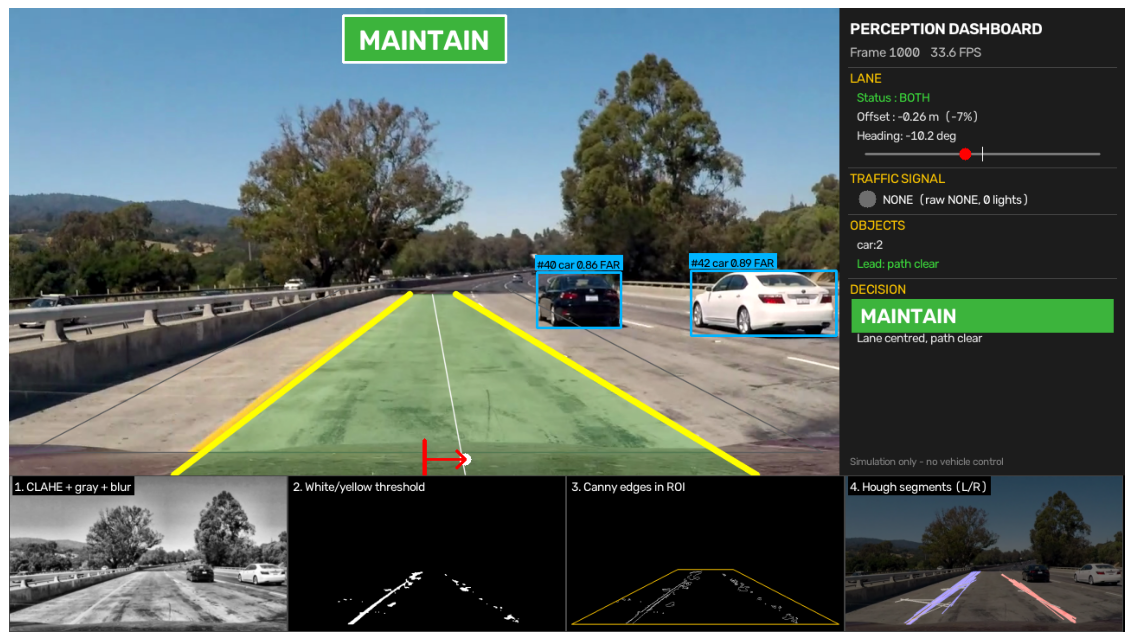

#40  car      conf=0.86 proximity=0.21 (FAR) in_path=False approaching=False
#42  car      conf=0.89 proximity=0.25 (FAR) in_path=False approaching=False
Decision: MAINTAIN - Lane centred, path clear


In [5]:
pipe = PerceptionPipeline(Config())
cap = cv2.VideoCapture('data/project_video.mp4')
for i in range(1001):
    ok, f = cap.read(); res = pipe.process_frame(f, i, render=(i == 1000))
cap.release()
plt.figure(figsize=(16, 9)); plt.imshow(rgb(res.dashboard)); plt.axis('off'); plt.show()
for t in res.tracks:
    print(f'#{t.track_id:<3} {t.label:<8} conf={t.conf:.2f} proximity={t.proximity:.2f} ({t.proximity_level}) in_path={t.in_path} approaching={t.approaching}')
print('Decision:', res.decision.action, '-', res.decision.reason)

## Decision scenarios on the synthetic video (STEER / SLOW DOWN / STOP)

[pipeline] YOLO model 'models/yolov8n.pt' loaded on mps


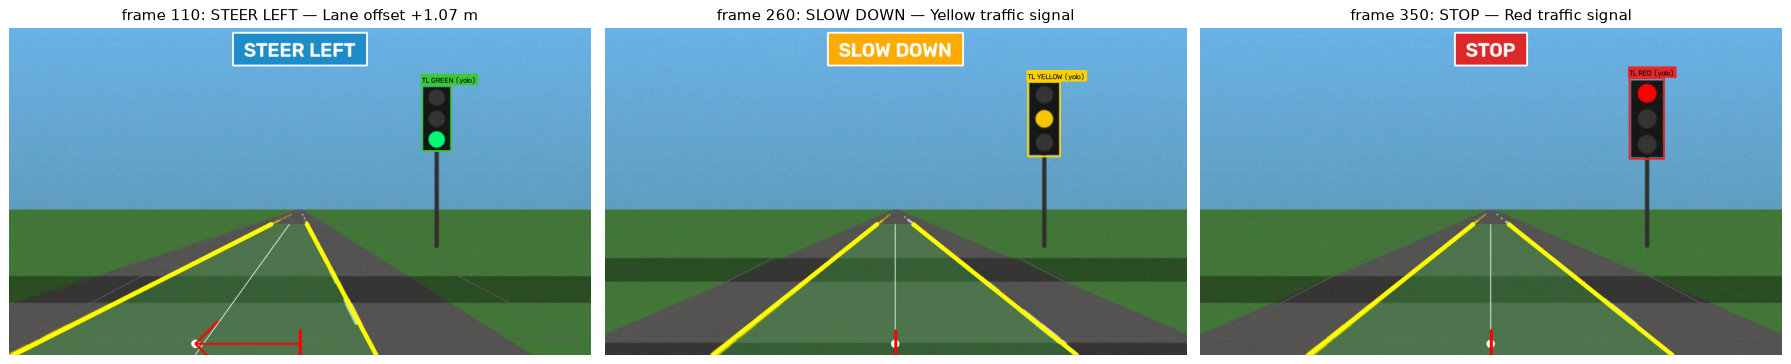

In [6]:
cfg_syn = Config(); cfg_syn.signal_mode = 'both'
pipe = PerceptionPipeline(cfg_syn)
cap = cv2.VideoCapture('data/synthetic_road.mp4'); shots = {}
for i in range(351):
    ok, f = cap.read(); r = pipe.process_frame(f, i, render=i in (110, 260, 350))
    if i in (110, 260, 350): shots[i] = r
cap.release()
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
for a, (i, r) in zip(ax, shots.items()):
    a.imshow(rgb(r.dashboard[:540, :960])); a.set_title(f'frame {i}: {r.decision.action} — {r.decision.reason}'); a.axis('off')
plt.tight_layout(); plt.show()

## Evaluation
Full run over the synthetic video (which has ground truth) and the evaluation metrics described in the synopsis.

In [7]:
from scripts.evaluate import evaluate
run_video(PerceptionPipeline(cfg_syn), 'data/synthetic_road.mp4', log_path='outputs/synthetic_road_log.csv')
summary = evaluate('outputs/synthetic_road_log.csv', 'data/synthetic_road_gt.csv')

[pipeline] YOLO model 'models/yolov8n.pt' loaded on mps
[run] frame 0/700    80.9 ms  lane=BOTH       signal=GREEN   objects= 0  -> MAINTAIN


[run] frame 50/700    21.9 ms  lane=BOTH       signal=GREEN   objects= 0  -> MAINTAIN


[run] frame 100/700    27.0 ms  lane=BOTH       signal=GREEN   objects= 0  -> STEER LEFT


[run] frame 150/700    21.6 ms  lane=BOTH       signal=GREEN   objects= 0  -> STEER LEFT


[run] frame 200/700    21.7 ms  lane=BOTH       signal=GREEN   objects= 0  -> MAINTAIN


[run] frame 250/700    22.6 ms  lane=BOTH       signal=YELLOW  objects= 0  -> SLOW DOWN


... (6 outputs left out)

[run] frame 600/700    22.1 ms  lane=BOTH       signal=GREEN   objects= 0  -> MAINTAIN


[run] frame 650/700    23.0 ms  lane=BOTH       signal=GREEN   objects= 0  -> MAINTAIN


[run] processed 700 frames in 15.9s (44.04 FPS overall)



=== Evaluation: synthetic_road (700 frames) ===
Speed     : 22.3 ms/frame (median 22.3, p95 23.2) -> 44.8 FPS
Lane      : detected 100.0%, both lines fresh 100.0%, jitter 0.0019 lane-widths/frame
            offset MAE vs ground truth 0.0058 lane widths
Objects   : 0.00/frame, mean conf -, 0 tracks, mean length 0.0 frames
Signal    : {'GREEN': 490, 'YELLOW': 60, 'RED': 150}, accuracy 99.1%
Decision  : {'MAINTAIN': 267, 'STEER LEFT': 110, 'SLOW DOWN': 60, 'STOP': 153, 'STEER RIGHT': 110}
            15.0 switches/min (raw rules: 15.0), accuracy 96.1%

plots + summary.json written to outputs/eval/synthetic_road/


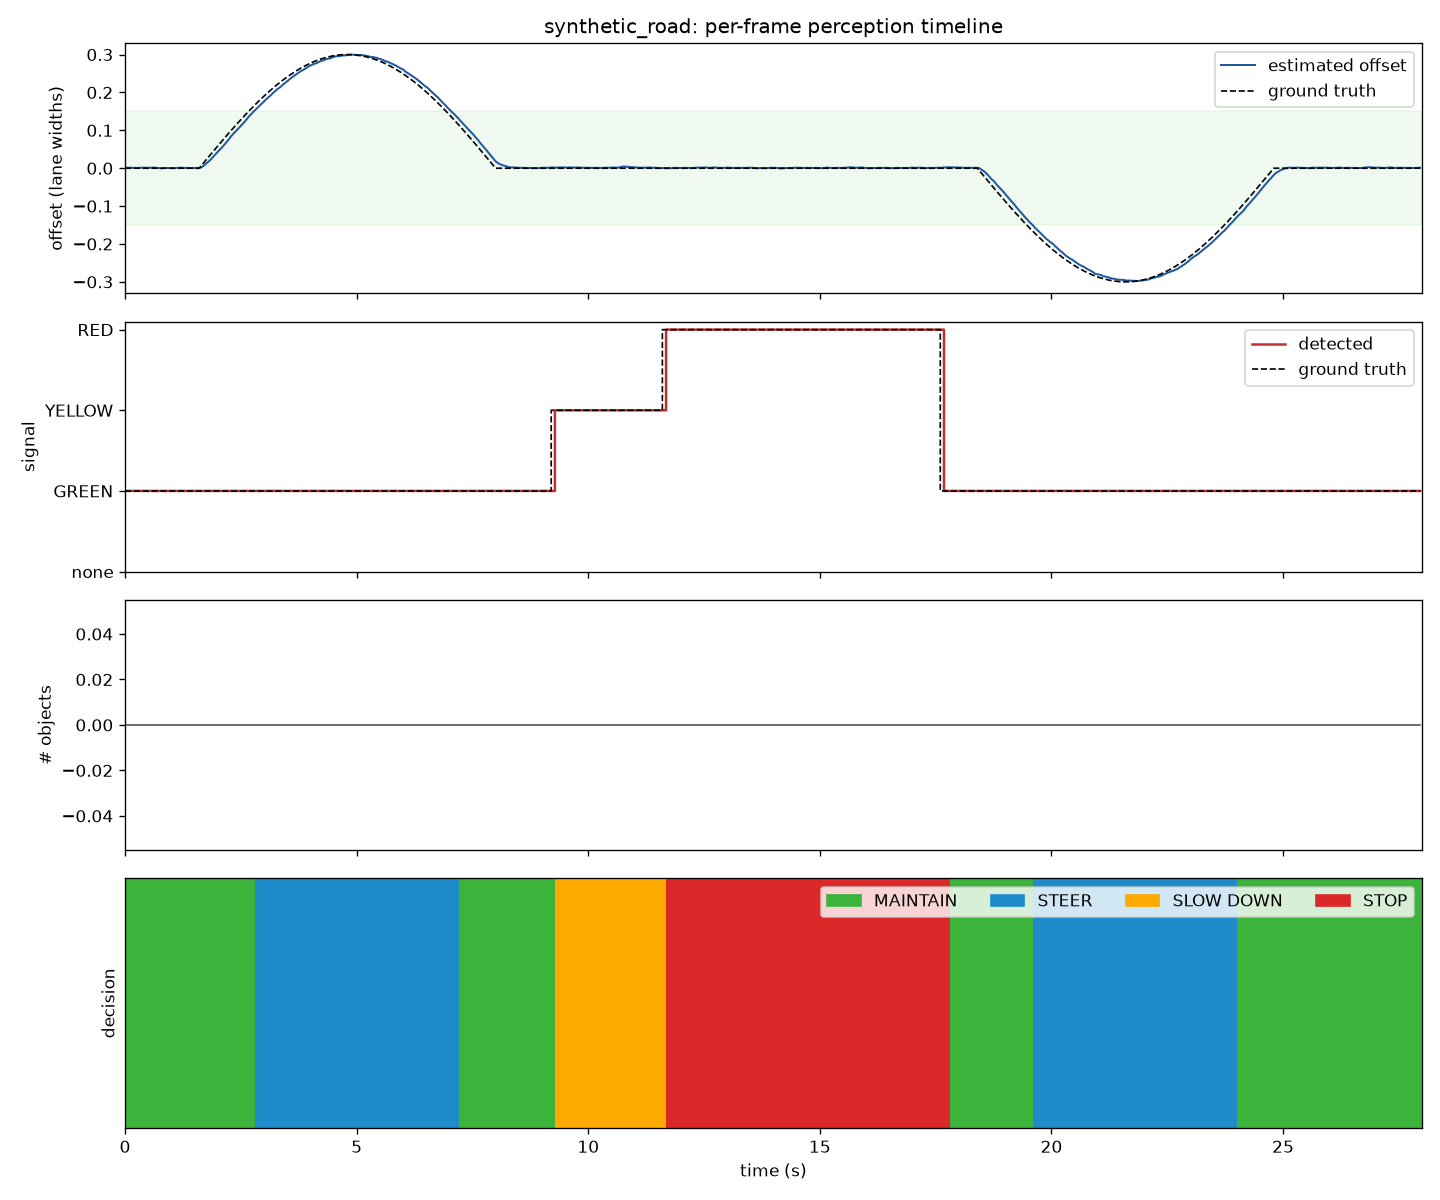

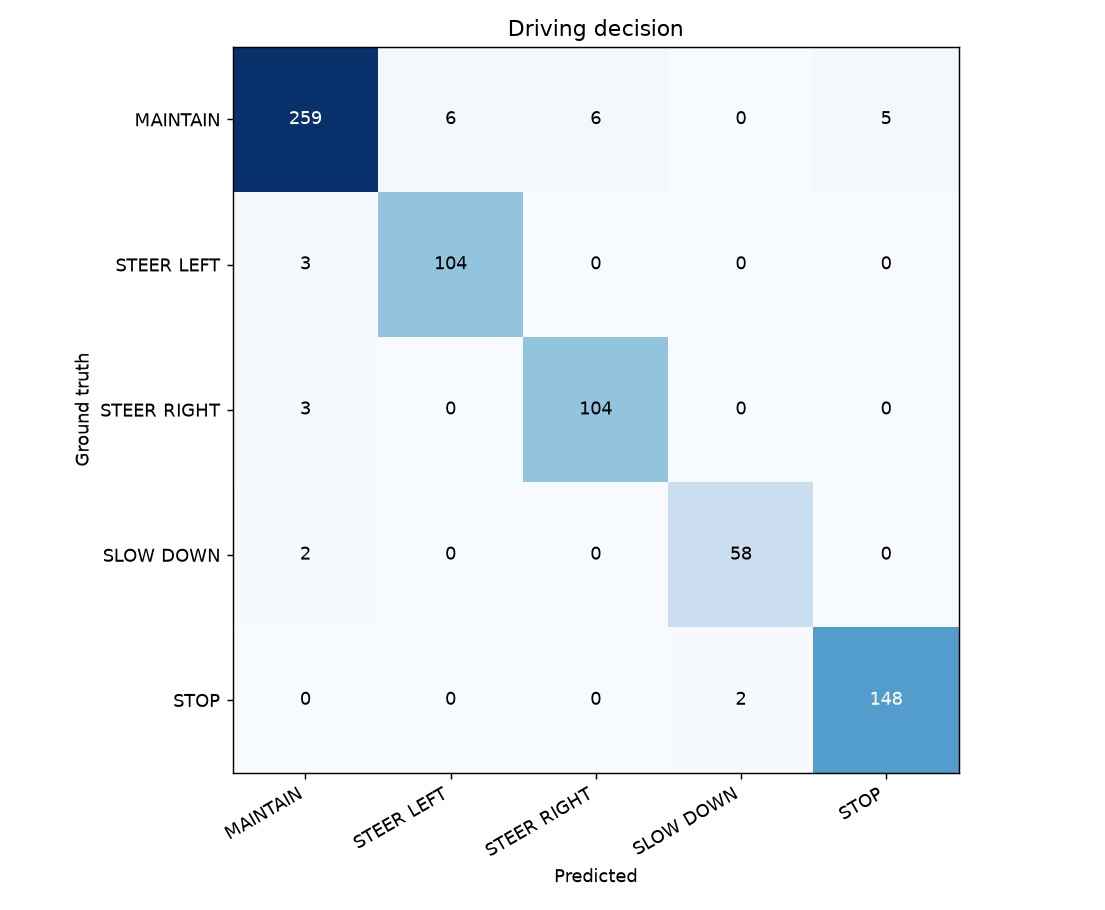

In [8]:
from IPython.display import Image, display
display(Image('outputs/eval/synthetic_road/timeline.png'))
display(Image('outputs/eval/synthetic_road/confusion_decision.png'))